# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

data_paths = [Path('../data/airbnb_london.csv'), Path('data/airbnb_london.csv')]
data_path = next((p for p in data_paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Keep airbnb_london.csv inside the repository data/ folder.')
df = pd.read_csv(data_path)
assert not df[['price', 'room_type', 'neighbourhood', 'reviews_per_month']].isna().any().any()
assert (df[['price','reviews_per_month']] >= 0).all().all()
print(f'Loaded {len(df):,} listings from {df.neighbourhood.nunique()} boroughs.')
display(df.describe().round(2))

Loaded 2,500 listings from 10 boroughs.


,price,minimum_nights,number_of_reviews,availability_365,reviews_per_month
count,2500.00,2500.00,2500.00,2500.00,2500.00
mean,148.58,14.82,147.91,183.69,2.02
std,110.89,8.40,86.32,105.54,2.00
min,20.47,1.00,0.00,0.00,0.00
25%,71.65,8.00,74.00,92.00,0.61
50%,117.46,15.00,145.00,182.00,1.42
75%,188.92,22.00,222.25,277.00,2.82
max,1032.43,29.00,299.00,364.00,15.22


In [2]:
# Follow the lecture convention: exclude prices above the 95th percentile.
p95 = df.price.quantile(0.95)
df_cap = df.loc[df.price <= p95].copy()
excluded = len(df) - len(df_cap)
print(f'Price threshold: £{p95:.2f}; retained {len(df_cap):,}; excluded {excluded}.')
display(df_cap.groupby('room_type').price.describe().round(2))

Price threshold: £372.66; retained 2,375; excluded 125.


,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,1251.0,176.30,75.65,28.05,119.64,163.42,223.51,372.61
Private room,942.0,87.30,39.53,20.92,59.01,78.57,105.96,277.93
Shared room,182.0,46.28,14.13,20.47,36.84,44.14,54.28,92.79


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


room_type
Entire home/apt    163.42
Private room        78.57


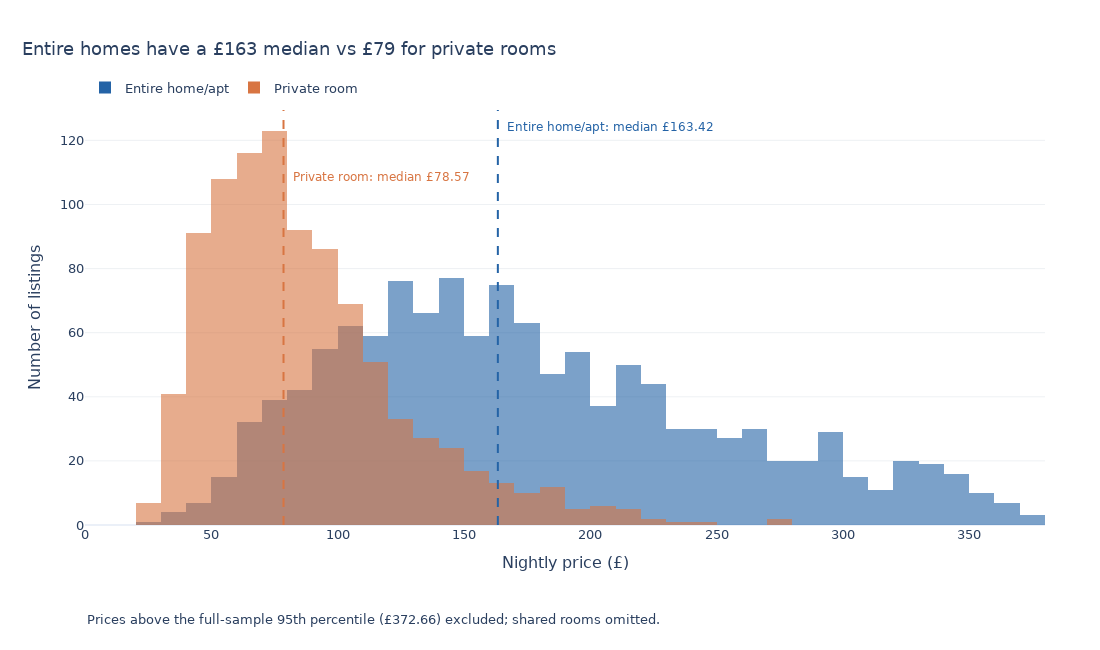

In [3]:
# Task 1 — common price bins and a median line for each room type.
room_types = ['Entire home/apt', 'Private room']
prices = df_cap[df_cap.room_type.isin(room_types)].copy()
medians = prices.groupby('room_type').price.median()
colors = {'Entire home/apt':'#2463A6', 'Private room':'#D87542'}
fig1 = px.histogram(
    prices, x='price', color='room_type',
    category_orders={'room_type':room_types}, color_discrete_map=colors,
    barmode='overlay', opacity=0.6,
    labels={'price':'Nightly price (£)', 'room_type':'Room type'},
    title=f'Entire homes have a £{medians[room_types[0]]:.0f} median vs £{medians[room_types[1]]:.0f} for private rooms',
    template='plotly_white', width=1100, height=650)
fig1.update_traces(xbins=dict(start=0,end=np.ceil(p95/10)*10,size=10))
for room,y in zip(room_types,[0.98,0.86]):
    fig1.add_vline(x=float(medians[room]),line_color=colors[room],line_dash='dash',line_width=2)
    fig1.add_annotation(x=float(medians[room]),y=y,yref='paper',
        text=f'{room}: median £{medians[room]:.2f}',showarrow=False,xanchor='left',xshift=7,
        font=dict(color=colors[room],size=12),bgcolor='rgba(255,255,255,0.9)')
fig1.add_annotation(x=0,y=-0.25,xref='paper',yref='paper',xanchor='left',showarrow=False,
    text=f'Prices above the full-sample 95th percentile (£{p95:.2f}) excluded; shared rooms omitted.')
fig1.update_layout(font=dict(family='Arial',size=13),title_x=0.02,
    legend=dict(orientation='h',x=0,y=1.09,title=None),
    margin=dict(l=85,r=55,t=110,b=125),yaxis=dict(title='Number of listings',gridcolor='#EEF1F4'),
    xaxis=dict(range=[0,np.ceil(p95/10)*10],showgrid=False))
assert set(prices.room_type)==set(room_types)
assert fig1.layout.barmode=='overlay' and all(t.marker.opacity==0.6 for t in fig1.data)
fig1.show()
print(medians.round(2).to_string())

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

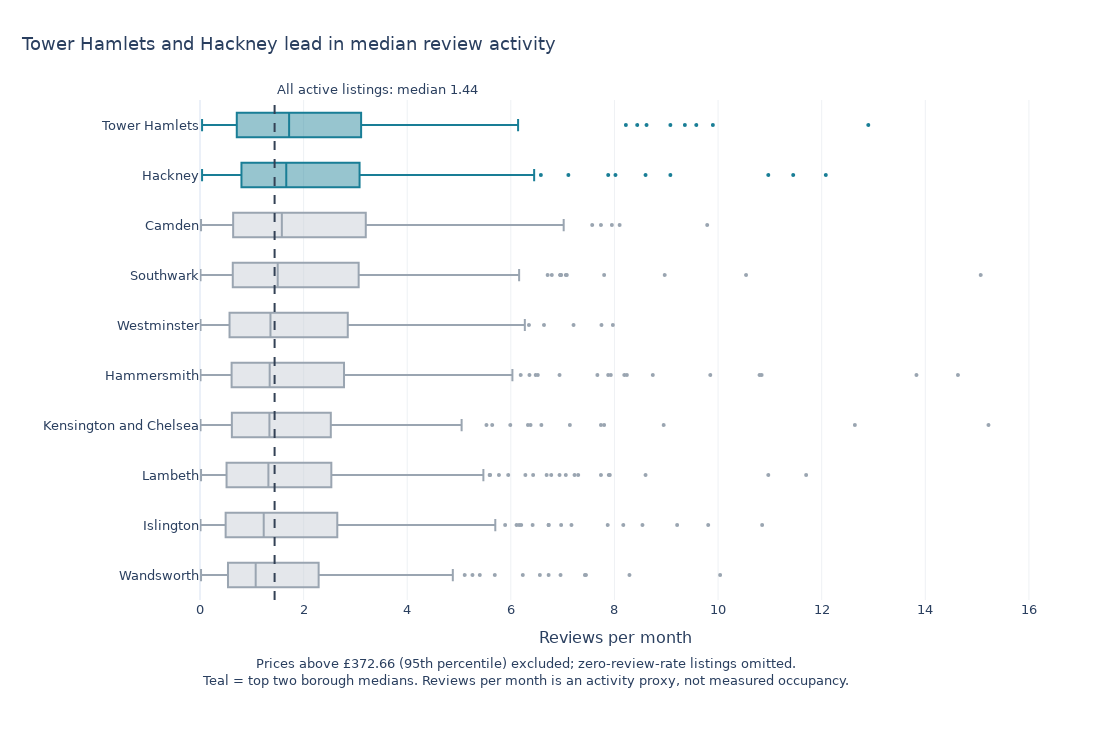

,Median reviews per month
neighbourhood,
Tower Hamlets,1.720
Hackney,1.665
Camden,1.580
Southwark,1.500
Westminster,1.360
Hammersmith,1.345
Kensington and Chelsea,1.340
Lambeth,1.320
Islington,1.230


In [4]:
# Task 2 — active listings only; order boroughs by their median activity.
activity = df_cap.loc[df_cap.reviews_per_month > 0].copy()
borough_medians = activity.groupby('neighbourhood').reviews_per_month.median().sort_values(ascending=False)
order = borough_medians.index.tolist()
top_two = order[:2]
overall_median = activity.reviews_per_month.median()
fig2 = go.Figure()
for borough in order:
    values = activity.loc[activity.neighbourhood==borough,'reviews_per_month']
    highlight = borough in top_two
    fig2.add_trace(go.Box(x=values,y=[borough]*len(values),name=borough,orientation='h',
        boxpoints='outliers',line=dict(color='#197E96' if highlight else '#9AA5B1'),
        fillcolor='rgba(25,126,150,0.45)' if highlight else 'rgba(206,212,219,0.55)',
        marker=dict(color='#197E96' if highlight else '#9AA5B1',size=4),
        hovertemplate=borough+'<br>Reviews per month: %{x:.2f}<extra></extra>',showlegend=False))
fig2.add_vline(x=float(overall_median),line_color='#334155',line_dash='dash',
    annotation_text=f'All active listings: median {overall_median:.2f}',annotation_position='top right',
    annotation_y=1.04,annotation_yref='paper')
fig2.add_annotation(x=0,y=-0.18,xref='paper',yref='paper',xanchor='left',showarrow=False,
    text=f'Prices above £{p95:.2f} (95th percentile) excluded; zero-review-rate listings omitted.<br>Teal = top two borough medians. Reviews per month is an activity proxy, not measured occupancy.')
fig2.update_layout(title=f'{top_two[0]} and {top_two[1]} lead in median review activity',
    template='plotly_white',width=1100,height=730,title_x=0.02,
    xaxis=dict(title='Reviews per month',rangemode='tozero',gridcolor='#EEF1F4'),
    yaxis=dict(title=None,categoryorder='array',categoryarray=order,autorange='reversed',showgrid=False),
    margin=dict(l=200,r=70,t=100,b=130),font=dict(family='Arial',size=13))
assert len(fig2.data)==activity.neighbourhood.nunique()
assert sum(t.line.color=='#197E96' for t in fig2.data)==2
assert activity.reviews_per_month.gt(0).all() and activity.price.le(p95).all()
fig2.show()
display(borough_medians.rename('Median reviews per month').to_frame())

### Interpretation and design choices

- Both charts exclude prices above the **full-sample 95th percentile**. This follows the exercise's filtering convention; values are removed, rather than replaced by the threshold.
- The histogram compares only entire homes/apartments and private rooms, using identical £10 bins, 0.6 opacity, and a separate annotated median for each group.
- The horizontal boxes show only positive reviews-per-month observations. Boroughs are ordered by their medians, with the top two highlighted and outliers retained as points. The dashed line gives the pooled median of the retained active listings.
- Reviews per month is a proxy for listing activity. It does not measure bookings or establish which borough has the highest occupancy.

**Source:** course-provided Airbnb London CSV from Dr. Dina Deifallah's class repository. Results describe this teaching sample, rather than all current London listings.